# Analyse de la transition énergétique (2000-2026)

## Questions métier
1. **Mix énergétique** : quels pays ont le plus réduit la part du charbon et le plus augmenté celle du solaire et de l'éolien depuis 2000 ?
2. **Mix et émissions** : les pays qui ont le plus augmenté leur part de renouvelables ont-ils réduit leurs émissions de CO2 par habitant ?
3. **Prix du carbone** : comment évolue le prix par marché, mois par mois, et où sont les ruptures (par exemple la crise énergétique de 2022) ?
4. **Température et CO2** : l'anomalie de température globale suit-elle le CO2 atmosphérique, et quelles régions se réchauffent le plus vite ?
5. **Événements climatiques** : les événements les plus graves surviennent-ils dans les années les plus chaudes, et la gravité dépend-elle du type d'événement ?

Source : Kaggle, *Global Climate & Energy Transition 2000-2026* .

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

prix = pd.read_csv("../data/processed/carbon_prices_propre.csv", parse_dates=["date"])
evenements = pd.read_csv("../data/processed/climate_events_propre.csv", parse_dates=["date"])
emissions = pd.read_csv("../data/processed/co2_emissions_propre.csv")
mix = pd.read_csv("../data/processed/energy_mix_propre.csv")
temperature = pd.read_csv("../data/processed/temperature_anomaly_propre.csv", parse_dates=["year_month"])

print(prix.shape, evenements.shape, emissions.shape, mix.shape, temperature.shape)

(15866, 5) (50, 11) (1350, 8) (1350, 14) (2528, 6)


## Question 1 : mix énergétique
Quels pays ont le plus réduit la part du charbon et le plus augmenté celle du solaire et de l'éolien depuis 2000 ?

In [2]:
mix["solaire_eolien_pct"] = mix["solar_pct"] + mix["wind_pct"]

mix_2000_2025 = mix[mix["year"].isin([2000, 2025])]

charbon = pd.pivot_table(mix_2000_2025, values="coal_pct", index="country", columns="year")
solaire_eolien = pd.pivot_table(mix_2000_2025, values="solaire_eolien_pct", index="country", columns="year")

baisse_charbon = (charbon[2000] - charbon[2025]).sort_values(ascending=False)
hausse_solaire_eolien = (solaire_eolien[2025] - solaire_eolien[2000]).sort_values(ascending=False)

print("Les 10 plus fortes baisses de la part du charbon (points de %) :")
print(baisse_charbon.head(10).round(1))
print()
print("Les 10 plus fortes hausses de la part solaire + éolien (points de %) :")
print(hausse_solaire_eolien.head(10).round(1))

Les 10 plus fortes baisses de la part du charbon (points de %) :
country
Australia         20.2
United States     16.8
United Kingdom    16.0
Mexico            15.3
Germany           14.6
China             14.6
Canada            13.8
South Africa      12.8
Ukraine           11.8
Belgium           11.0
dtype: float64

Les 10 plus fortes hausses de la part solaire + éolien (points de %) :
country
Germany           25.4
Australia         23.7
Belgium           19.8
United Kingdom    19.6
Denmark           18.5
Sweden            17.5
Spain             17.4
Poland            17.4
Finland           16.7
Brazil            16.5
dtype: float64


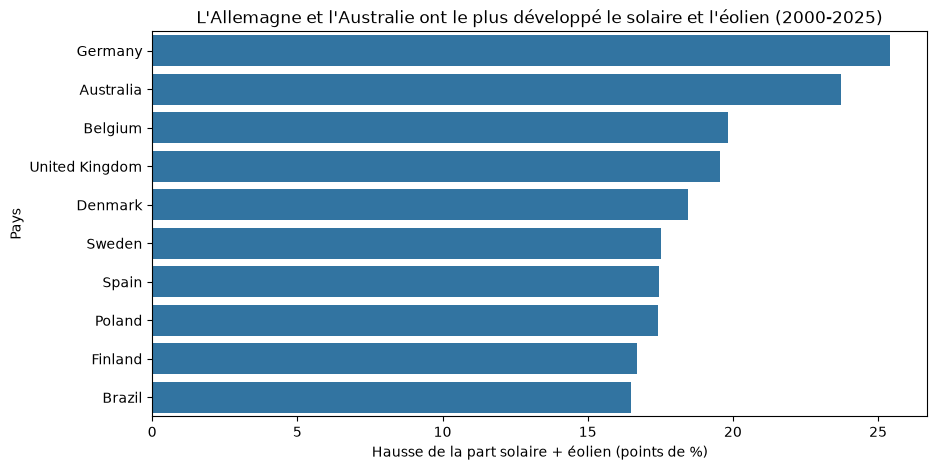

In [4]:
top10 = hausse_solaire_eolien.head(10)
tableau = pd.DataFrame({"pays": top10.index, "hausse": top10.values})

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=tableau, x="hausse", y="pays", ax=ax)
ax.set_title("L'Allemagne et l'Australie ont le plus développé le solaire et l'éolien (2000-2025)")
ax.set_xlabel("Hausse de la part solaire + éolien (points de %)")
ax.set_ylabel("Pays")
fig.savefig("../figures/q1_solaire_eolien.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q1 :**
- **Charbon :** l'Australie (-20,2 points de %), les États-Unis (-16,8) et le Royaume-Uni (-16,0) sont les pays où la part du charbon a le plus reculé entre 2000 et 2025. Viennent ensuite le Mexique (-15,3), l'Allemagne et la Chine (-14,6 chacune).
- **Solaire et éolien :** l'Allemagne (+25,4 points) et l'Australie (+23,7) sont loin devant, suivies de la Belgique (+19,8) et du Royaume-Uni (+19,6). Huit des dix pays sont européens.
- **Lien entre les deux :** quatre pays figurent dans les deux classements : l'Australie, l'Allemagne, le Royaume-Uni et la Belgique. Ils ont donc réduit le charbon tout en développant fortement solaire et éolien. À l'inverse, les États-Unis, le Mexique, la Chine, le Canada, l'Afrique du Sud et l'Ukraine ont fortement réduit le charbon sans figurer parmi les dix pays où solaire et éolien progressent le plus, et la Pologne, le Danemark, la Suède, l'Espagne, la Finlande et le Brésil sont dans le cas inverse.

## Question 2 : mix et émissions
Les pays qui ont le plus augmenté leur part de renouvelables ont-ils réduit leurs émissions de CO2 par habitant ?

In [5]:
nb_avant = len(mix)
mix_emissions = mix.merge(
    emissions[["country", "year", "co2_per_capita_t"]],
    on=["country", "year"], how="left", validate="one_to_one",
)
assert len(mix_emissions) == nb_avant

print("Lignes avant :", nb_avant, "- après :", len(mix_emissions))
print("co2_per_capita_t manquants après jointure :", mix_emissions["co2_per_capita_t"].isna().sum())

Lignes avant : 1350 - après : 1350
co2_per_capita_t manquants après jointure : 0


In [6]:
mix_emissions_2000_2025 = mix_emissions[mix_emissions["year"].isin([2000, 2025])]

renouvelables = pd.pivot_table(mix_emissions_2000_2025, values="renewables_total_pct", index="country", columns="year")
co2_par_habitant = pd.pivot_table(mix_emissions_2000_2025, values="co2_per_capita_t", index="country", columns="year")

variations = pd.DataFrame({
    "hausse_renouvelables": renouvelables[2025] - renouvelables[2000],
    "variation_co2_par_habitant": co2_par_habitant[2025] - co2_par_habitant[2000],
})

mediane = variations["hausse_renouvelables"].median()
variations["forte_hausse"] = variations["hausse_renouvelables"] > mediane

variations.groupby("forte_hausse").agg(
    pays=("variation_co2_par_habitant", "size"),
    variation_moyenne=("variation_co2_par_habitant", "mean"),
).round(2)

,pays,variation_moyenne
forte_hausse,,
False,25,2.44
True,25,-2.61


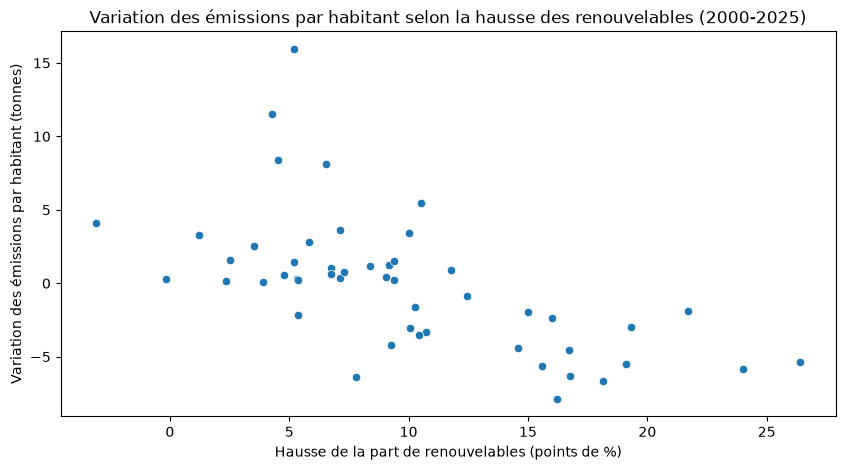

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=variations, x="hausse_renouvelables", y="variation_co2_par_habitant", ax=ax)
ax.set_title("Les pays où les renouvelables ont le plus progressé ont réduit leurs émissions par habitant (2000-2025)")
ax.set_xlabel("Hausse de la part de renouvelables (points de %)")
ax.set_ylabel("Variation des émissions par habitant (tonnes)")
fig.savefig("../figures/q2_renouvelables_emissions.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q2 :** oui, globalement. En séparant les 50 pays en deux groupes de 25 selon la hausse de leur part de renouvelables entre 2000 et 2025 :
- les 25 pays à **forte hausse** ont vu leurs émissions par habitant **baisser** de 2,61 tonnes en moyenne ;
- les 25 pays à **faible hausse** les ont vues **augmenter** de 2,44 tonnes en moyenne.

Le nuage de points confirme cette tendance : au-delà d'environ 14 points de hausse des renouvelables, tous les pays du graphique ont des émissions par habitant en baisse (entre environ -2 et -8 tonnes). Les plus fortes augmentations d'émissions (jusqu'à environ +16 tonnes) se trouvent parmi des pays où les renouvelables ont peu progressé (moins de 7 points).
Ce lien reste une tendance, pas une preuve de cause : des pays comme l'Australie ou l'Allemagne ont aussi changé d'autres choses (industrie, énergie, population) qui ont pu jouer sur leurs émissions.

## Question 3 : prix du carbone
Comment évolue le prix par marché, mois par mois, et où sont les ruptures (par exemple la crise énergétique de 2022) ?

Les marchés ont des devises différentes et des dates de départ différentes. On compare donc les marchés depuis août 2021 (tous existent à cette date), en **base 100** : chaque prix est divisé par celui d'août 2021. On passe du jour au mois avec `resample`.

In [8]:
prix_depuis_2021 = prix[prix["date"] >= "2021-08-01"]

prix_par_jour = pd.pivot_table(prix_depuis_2021, values="price", index="date", columns="market")
prix_par_mois = prix_par_jour.resample("MS").mean()
prix_base_100 = prix_par_mois / prix_par_mois.iloc[0] * 100

print(prix_base_100.round(0).head())
print()
print("Les 3 mois les plus chers de l'EU ETS (en euros) :")
print(prix_par_mois["EU_ETS"].sort_values(ascending=False).head(3).round(1))

market      California  China_ETS  EU_ETS   RGGI  UK_ETS
date                                                    
2021-08-01       100.0      100.0   100.0  100.0   100.0
2021-09-01       102.0      103.0   108.0  102.0   107.0
2021-10-01       104.0      105.0   117.0  105.0   112.0
2021-11-01       106.0      107.0   121.0  108.0   117.0
2021-12-01       110.0      110.0   130.0  111.0   123.0

Les 3 mois les plus chers de l'EU ETS (en euros) :
date
2023-01-01    100.0
2022-10-01     99.7
2023-02-01     99.7
Name: EU_ETS, dtype: float64


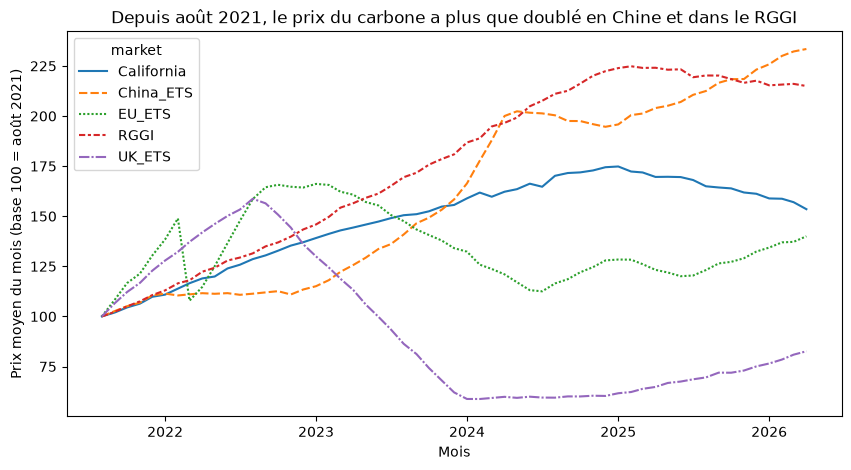

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=prix_base_100, ax=ax)
ax.set_title("Depuis août 2021, le prix du carbone a plus que doublé en Chine et dans le RGGI")
ax.set_xlabel("Mois")
ax.set_ylabel("Prix moyen du mois (base 100 = août 2021)")
fig.savefig("../figures/q3_prix_carbone.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
print("Valeur en avril 2026 (base 100) :")
print(prix_base_100.iloc[-1].round(0))
print()
print("Valeur la plus basse du UK_ETS :")
print(prix_base_100["UK_ETS"].sort_values().head(1).round(0))
print()
print("EU_ETS début 2022 :")
print(prix_base_100["EU_ETS"].loc["2022-01-01":"2022-05-01"].round(0))

Valeur en avril 2026 (base 100) :
market
California    154.0
China_ETS     233.0
EU_ETS        140.0
RGGI          215.0
UK_ETS         83.0
Name: 2026-04-01 00:00:00, dtype: float64

Valeur la plus basse du UK_ETS :
date
2024-02-01    59.0
Name: UK_ETS, dtype: float64

EU_ETS début 2022 :
date
2022-01-01    138.0
2022-02-01    149.0
2022-03-01    108.0
2022-04-01    115.0
2022-05-01    125.0
Freq: MS, Name: EU_ETS, dtype: float64


**Conclusion Q3 :** depuis août 2021 (base 100), les prix du carbone ont évolué très différemment selon les marchés.
- **Les plus fortes hausses :** en avril 2026, la Chine (environ 233) et le RGGI (environ 215) ont plus que doublé. La Californie est à environ 153, après un pic vers 175 fin 2024, et l'EU ETS à environ 140.
- **Le Royaume-Uni :** c'est le seul marché sous sa valeur de départ (environ 82). Son UK ETS a monté jusqu'à environ 160 mi-2022, puis chuté à environ 59 début 2024.
- **Rupture de 2022 :** l'EU ETS chute nettement au début de 2022 (d'environ 148 à environ 108) avant de remonter vite. Ses mois les plus chers sont janvier 2023 (100,0 €), octobre 2022 et février 2023 (99,7 € chacun), ce qui confirme que les prix élevés de l'EU ETS se concentrent sur 2022-2023.
- **Un constat :** à partir de 2023, l'EU ETS et le UK ETS baissent alors que la Chine et le RGGI continuent de monter : les marchés ne suivent pas tous la même trajectoire.

## Question 4 : température et CO2
L'anomalie de température globale suit-elle le CO2 atmosphérique, et quelles régions se réchauffent le plus vite ?

Le ppm n'existe que pour la région « Global » : on l'utilise pour le premier graphique. 2026 est exclue des moyennes annuelles (année incomplète). Pour comparer les régions, on découpe les années en 3 périodes avec `pd.cut`.

In [12]:
temp_globale = temperature[temperature["region"] == "Global"]
temp_annuelle = temp_globale[temp_globale["year"] < 2026].groupby("year").agg(
    anomalie=("temp_anomaly_c", "mean"),
    co2_ppm=("co2_ppm", "mean"),
)
print(temp_annuelle.round(2).head())

temperature["periode"] = pd.cut(
    temperature["year"],
    bins=[1999, 2009, 2019, 2025],
    labels=["2000-2009", "2010-2019", "2020-2025"],
)
regions_par_periode = pd.pivot_table(
    temperature, values="temp_anomaly_c", index="region", columns="periode", aggfunc="mean",
)
regions_par_periode.round(2)

      anomalie  co2_ppm
year                   
2000      0.45   369.33
2001      0.51   371.49
2002      0.61   373.34
2003      0.65   375.24
2004      0.56   377.14


periode,2000-2009,2010-2019,2020-2025
region,,,
Arctic,2.06,2.78,3.67
Asia,0.74,0.99,1.30
Europe,0.97,1.31,1.73
Global,0.59,0.80,1.04
North America,0.86,1.15,1.52
Northern Hemisphere,0.78,1.03,1.36
Southern Hemisphere,0.45,0.59,0.77
Tropics,0.39,0.52,0.67


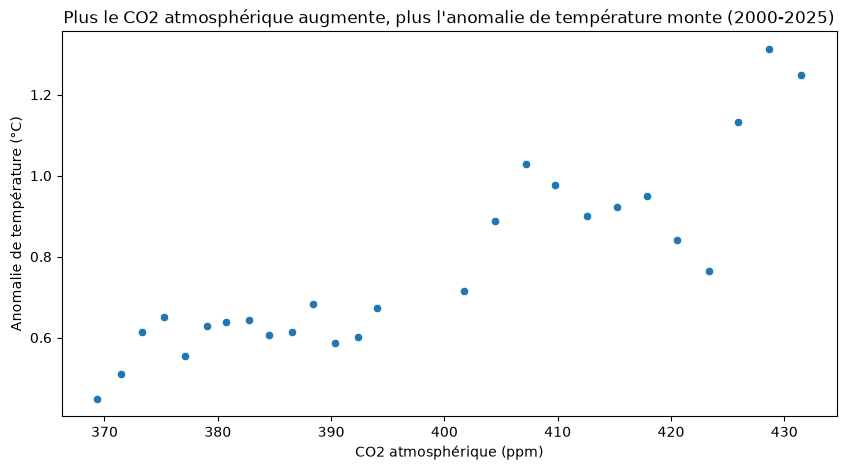

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=temp_annuelle, x="co2_ppm", y="anomalie", ax=ax)
ax.set_title("Plus le CO2 atmosphérique augmente, plus l'anomalie de température monte (2000-2025)")
ax.set_xlabel("CO2 atmosphérique (ppm)")
ax.set_ylabel("Anomalie de température (°C)")
fig.savefig("../figures/q4_temperature_co2.png", dpi=150, bbox_inches="tight")
plt.show()

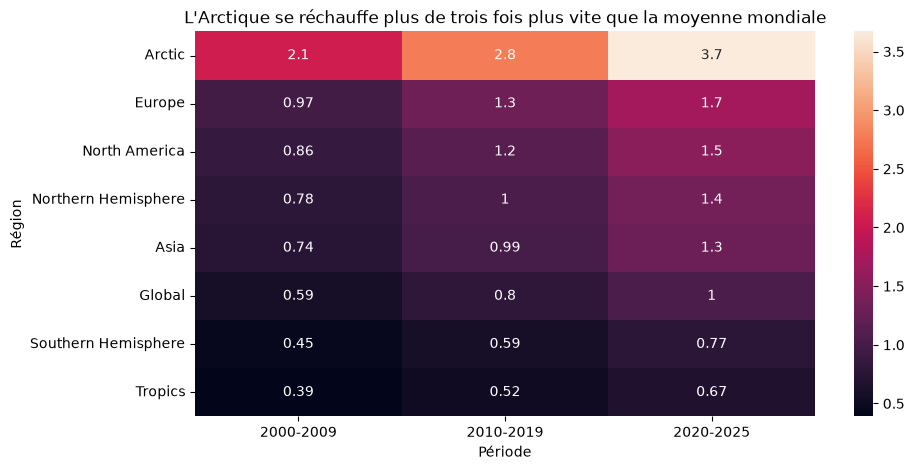

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(regions_par_periode.sort_values("2020-2025", ascending=False), annot=True, ax=ax)
ax.set_title("L'Arctique se réchauffe plus de trois fois plus vite que la moyenne mondiale")
ax.set_xlabel("Période")
ax.set_ylabel("Région")
fig.savefig("../figures/q4_regions_periodes.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q4 :**
- **CO2 et température :** oui, ils montent ensemble. Entre 2000 et 2025, le CO2 atmosphérique passe d'environ 369 à environ 430 ppm, et l'anomalie de température globale d'environ 0,45 °C à plus de 1,2 °C (par rapport à la période de référence 1951-1980 indiquée dans le fichier). Le nuage de points monte de gauche à droite, mais pas de façon régulière : certaines années autour de 420 ppm sont moins chaudes que des années à 410 ppm.
- **Régions :** l'Arctique se réchauffe de loin le plus vite. Son anomalie moyenne passe de 2,06 °C (2000-2009) à 3,67 °C (2020-2025), soit +1,61 °C, plus de trois fois la hausse mondiale (+0,45 °C). Viennent ensuite l'Europe (+0,76 °C) et l'Amérique du Nord (+0,66 °C). Les régions qui se réchauffent le moins sont l'hémisphère sud (+0,32 °C) et les tropiques (+0,28 °C). L'hémisphère nord (+0,58 °C) se réchauffe presque deux fois plus vite que l'hémisphère sud.
- **Prudence :** deux courbes qui montent ensemble ne prouvent pas que l'une cause l'autre, et on ne compare ici que 26 points annuels.

## Question 5 : événements climatiques
Les événements les plus graves surviennent-ils dans les années les plus chaudes, et la gravité dépend-elle du type d'événement ?

On joint les événements à l'anomalie annuelle globale (calculée à la question 4) sur l'année. Les régions des événements ne sont pas comparables à celles de la température, donc on joint sur l'année seulement.

In [17]:
temp_pour_jointure = temp_annuelle[["anomalie"]].reset_index()

nb_avant = len(evenements)
evenements_temp = evenements.merge(temp_pour_jointure, on="year", how="left", validate="many_to_one")
assert len(evenements_temp) == nb_avant

print("Lignes avant :", nb_avant, "- après :", len(evenements_temp))
print("Événements sans anomalie (année 2026) :", evenements_temp["anomalie"].isna().sum())

Lignes avant : 50 - après : 50
Événements sans anomalie (année 2026) : 2


In [18]:
evenements_valides = evenements_temp.dropna(subset=["anomalie"]).copy()
print("Événements utilisés :", len(evenements_valides))

mediane = evenements_valides["anomalie"].median()
evenements_valides["annee_chaude"] = evenements_valides["anomalie"] > mediane

print(evenements_valides.groupby("annee_chaude").agg(
    evenements=("severity_score", "size"),
    gravite_moyenne=("severity_score", "mean"),
).round(2))
print()
print(evenements_valides.groupby("event_type").agg(
    evenements=("severity_score", "size"),
    gravite_moyenne=("severity_score", "mean"),
).sort_values("gravite_moyenne", ascending=False).round(2))

Événements utilisés : 48
              evenements  gravite_moyenne
annee_chaude                             
False                 26             7.92
True                  22             8.00

               evenements  gravite_moyenne
event_type                                
temperature             2             9.00
tsunami                 2             9.00
earthquake              3             8.33
hurricane               7             8.14
drought                 1             8.00
typhoon                 1             8.00
heatwave_fire           1             8.00
flood                   6             8.00
policy                 11             7.91
wildfire                7             7.57
heat                    4             7.50
heatwave                2             7.50
winter_storm            1             7.00


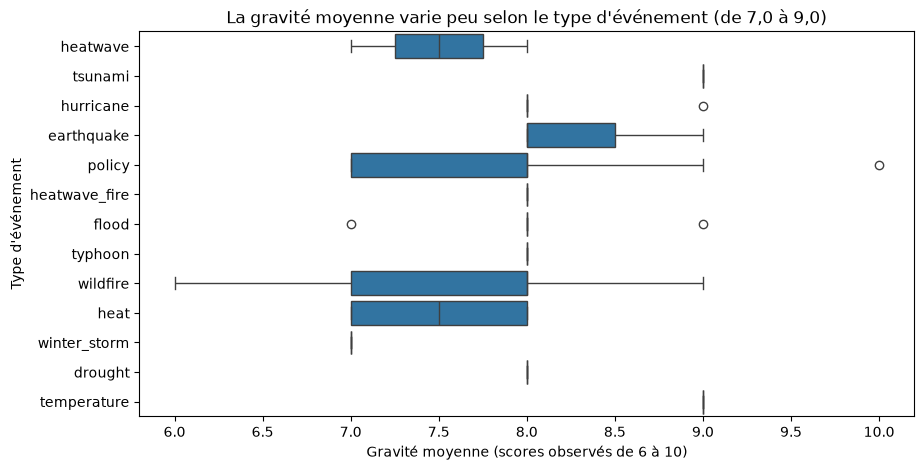

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=evenements_valides, x="severity_score", y="event_type", ax=ax)
ax.set_title("La gravité moyenne varie peu selon le type d'événement (de 7,0 à 9,0)")
ax.set_xlabel("Gravité moyenne (scores observés de 6 à 10)")
ax.set_ylabel("Type d'événement")
fig.savefig("../figures/q5_gravite_par_type.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion Q5 :**
- **Années chaudes :** non, dans ces données. Les 22 événements des années chaudes (anomalie au-dessus de la médiane) ont une gravité moyenne de 8,00, contre 7,92 pour les 26 autres : l'écart est quasi nul.
- **Type d'événement :** la gravité moyenne varie peu, de 7,0 (tempête d'hiver) à 9,0 (tsunami et événements de température). Ces deux types arrivent en tête avec seulement 2 événements chacun, donc ce classement est fragile. Parmi les types les plus nombreux, l'ouragan (7 événements) a une gravité moyenne de 8,14, les inondations (6) de 8,00, les décisions politiques (11) de 7,91 et les feux de forêt (7) de 7,57.
- **Limite :** avec 48 événements répartis en 13 types, la plupart des types ont trop peu de cas pour conclure sur eux.

## Conclusions générales
1. **Mix énergétique :** l'Australie (-20,2 points de charbon) a le plus réduit le charbon, et l'Allemagne (+25,4 points) a le plus développé solaire et éolien. Quatre pays figurent dans les deux classements : l'Australie, l'Allemagne, le Royaume-Uni et la Belgique.
2. **Mix et émissions :** oui. Les 25 pays à forte hausse de renouvelables ont réduit leurs émissions par habitant de 2,61 tonnes en moyenne, alors que les 25 autres les ont augmentées de 2,44 tonnes.
3. **Prix du carbone :** depuis août 2021, les prix ont plus que doublé en Chine et dans le RGGI, alors que le UK ETS est resté sous sa valeur de départ. L'EU ETS a connu une rupture début 2022, et ses mois les plus chers sont en 2022-2023.
4. **Température et CO2 :** les deux montent ensemble depuis 2000, mais pas de façon régulière. L'Arctique se réchauffe le plus vite (+1,61 °C entre 2000-2009 et 2020-2025), plus de trois fois la hausse mondiale.
5. **Événements climatiques :** non, la gravité des événements est quasi identique les années chaudes (8,00) et les autres (7,92), et varie peu selon le type.

## Limites de l'analyse
- L'année 2026 est incomplète (jusqu'au 30/04/2026) : elle est exclue des comparaisons annuelles.
- Les prix du carbone ont des devises différentes : on compare des évolutions en base 100, pas des niveaux.
- La population est arrondie à 0,1 million, ce qui rend les petits pays moins précis.
- Seulement 50 pays et 48 événements utilisables : les résultats ne valent pas pour le monde entier, et la plupart des types d'événements ont très peu de cas.
- Une relation observée entre deux courbes ne prouve pas une cause.